In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('food_delivery_orders.csv')
df['order_date'] = pd.to_datetime(df['order_date'])

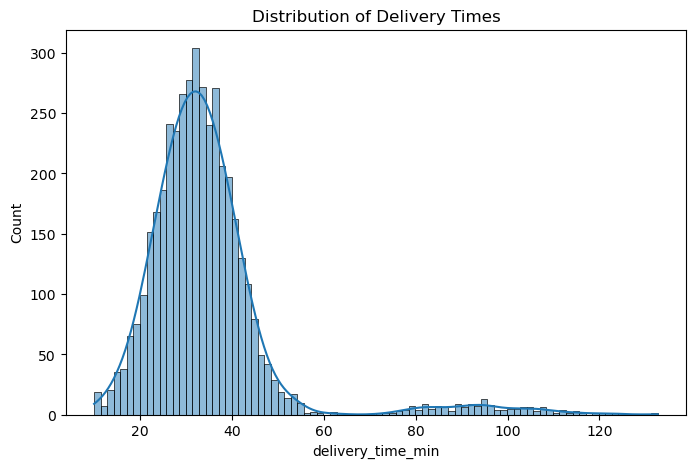

Skewness: 2.877 | Mean: 34.54 | Median: 32.50


In [3]:
# Task 1

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='delivery_time_min', kde=True)
plt.title('Distribution of Delivery Times')
plt.show()

skewness = df['delivery_time_min'].skew()
mean_val = df['delivery_time_min'].mean()
median_val = df['delivery_time_min'].median()
print(f"Skewness: {skewness:.3f} | Mean: {mean_val:.2f} | Median: {median_val:.2f}")

#### Management should advertise the median (32.50 minutes) as the "typical delivery time" because the distribution is strongly right-skewed with a skewness value of 2.877. Using the median provides a more honest reflection of the typical customer experience, as it is not artificially inflated by a few extremely late outlier deliveries (which are visible in the long tail stretching from 80 to over 120 minutes).

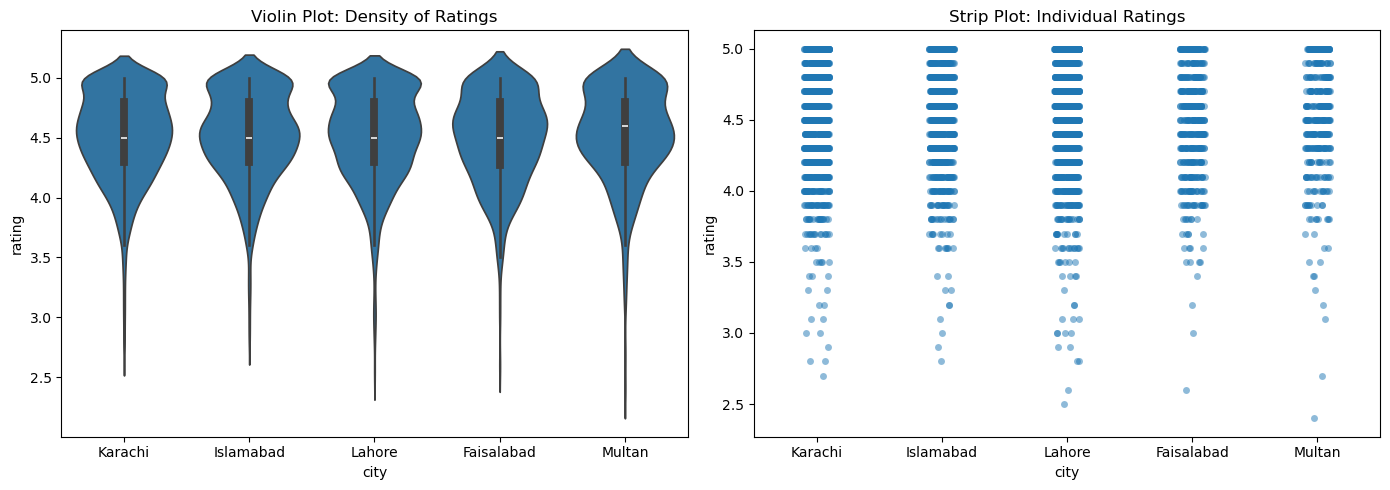

In [4]:
# Task 2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.violinplot(data=df, x='city', y='rating', ax=axes[0])
axes[0].set_title('Violin Plot: Density of Ratings')

sns.stripplot(data=df, x='city', y='rating', jitter=True, alpha=0.5, ax=axes[1])
axes[1].set_title('Strip Plot: Individual Ratings')

plt.tight_layout()
plt.show()

#### Multan shows the most inconsistent customer experience, as its violin plot reveals a highly distinct bimodal pattern (an hourglass shape) with two clear peaks. This is confirmed by the strip plot, which shows a visible gap in the data, indicating that rather than clustering around a single average, customers in this region experience heavily polarized service—they either rate the delivery very highly or notably lower.

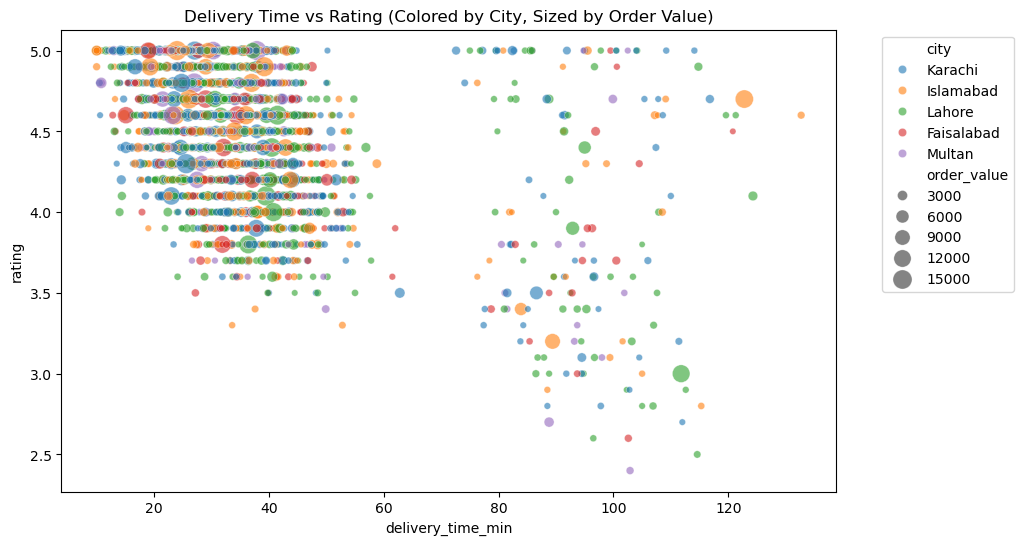

In [5]:
# Task 3

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='delivery_time_min', y='rating', 
                hue='city', size='order_value', sizes=(20, 200), alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.title('Delivery Time vs Rating (Colored by City, Sized by Order Value)')
plt.show()

#### The 4-variable encoding reveals that across all cities, the largest dots (high-value orders) consistently cluster towards the top-left. This pattern shows that high-value orders overwhelmingly receive faster deliveries (under 60 minutes) and higher ratings, whereas the smaller dots (lower-value orders) are much more widely scattered into the longer delivery times and lower ratings. This nuance—that expensive orders seem to get priority or better service—would have been hidden without mapping size alongside the other variables.

In [6]:
# Task 4

num_cols = df.select_dtypes(include=['number']).columns
pearson_corr = df[num_cols].corr(method='pearson')
spearman_corr = df[num_cols].corr(method='spearman')

print("--- Pearson Correlation ---")
print(pearson_corr)
print("\n--- Spearman Correlation ---")
print(spearman_corr)

--- Pearson Correlation ---
                   order_value  discount_percent  delivery_time_min    rating  \
order_value           1.000000         -0.011191           0.002202  0.003122   
discount_percent     -0.011191          1.000000           0.013286 -0.006129   
delivery_time_min     0.002202          0.013286           1.000000 -0.445474   
rating                0.003122         -0.006129          -0.445474  1.000000   
profit_per_order     -0.657144         -0.081982          -0.030879  0.014360   

                   profit_per_order  
order_value               -0.657144  
discount_percent          -0.081982  
delivery_time_min         -0.030879  
rating                     0.014360  
profit_per_order           1.000000  

--- Spearman Correlation ---
                   order_value  discount_percent  delivery_time_min    rating  \
order_value           1.000000          0.007783          -0.020271  0.004487   
discount_percent      0.007783          1.000000           0.0195

#### The greatest disagreement is between order_value and profit_per_order (Spearman is +0.673, Pearson is -0.657). This severe inversion is driven by a handful of extreme outliers—likely a few expensive orders with massive losses—that drag down the Pearson score. These extreme orders should be dropped before reporting; otherwise, management will be misled into believing larger orders generally cause losses.

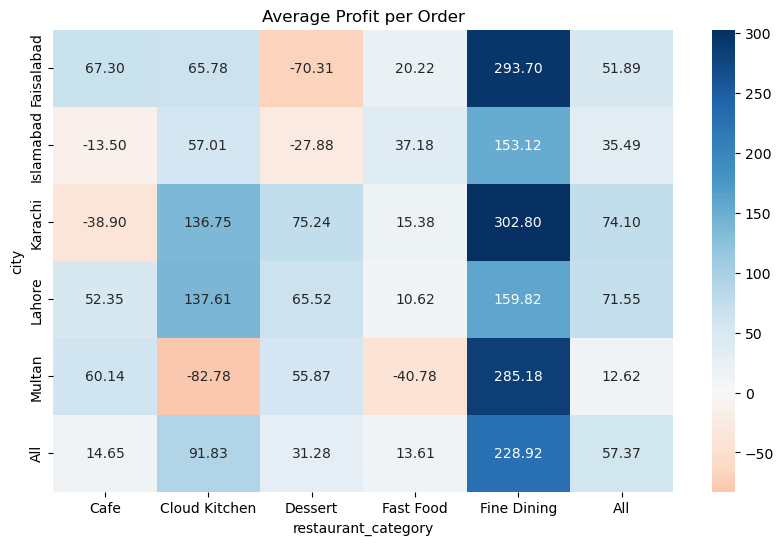

In [7]:
# Task 5

pivot = pd.pivot_table(df, index='city', columns='restaurant_category', 
                       values='profit_per_order', aggfunc='mean', margins=True)

plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, cmap='RdBu', center=0, fmt=".2f")
plt.title('Average Profit per Order')
plt.show()

#### The most profitable combination per order is Fine Dining in Karachi:
##### This combination is also the top revenue generator.


C:\Users\armug\AppData\Local\Temp\ipykernel_13460\3393377535.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_rating = df_time['rating'].resample('M').mean()


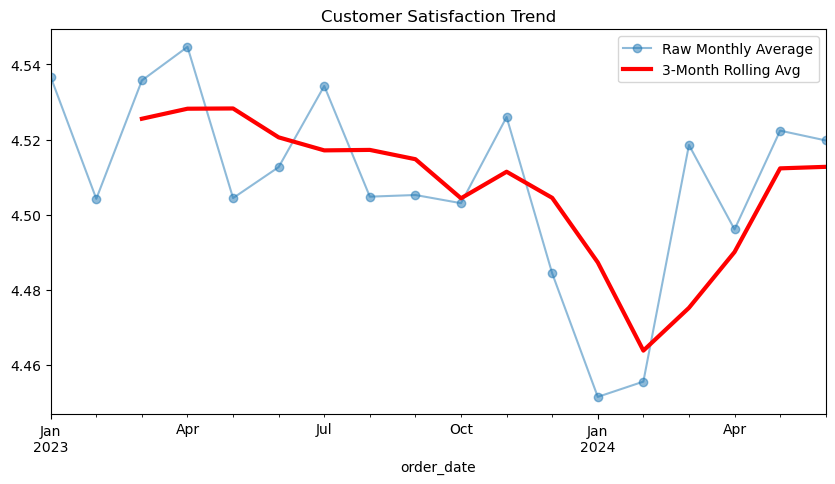

In [8]:
# Task 6

df_time = df.set_index('order_date')
monthly_rating = df_time['rating'].resample('M').mean()
rolling_rating = monthly_rating.rolling(window=3).mean()

plt.figure(figsize=(10, 5))
monthly_rating.plot(label='Raw Monthly Average', marker='o', alpha=0.5)
rolling_rating.plot(label='3-Month Rolling Avg', color='red', linewidth=3)
plt.title('Customer Satisfaction Trend')
plt.legend()
plt.show()

#### Once the month-to-month noise is smoothed out using a 3-month rolling average, customer satisfaction reveals a sustained downward trend throughout 2023 followed by a sharp upward recovery in early 2024. 
#### Relying solely on the raw monthly line would have masked this broader pattern, as its extreme, erratic spikes falsely suggest random, chaotic volatility rather than a clear cycle of decline and rebound.

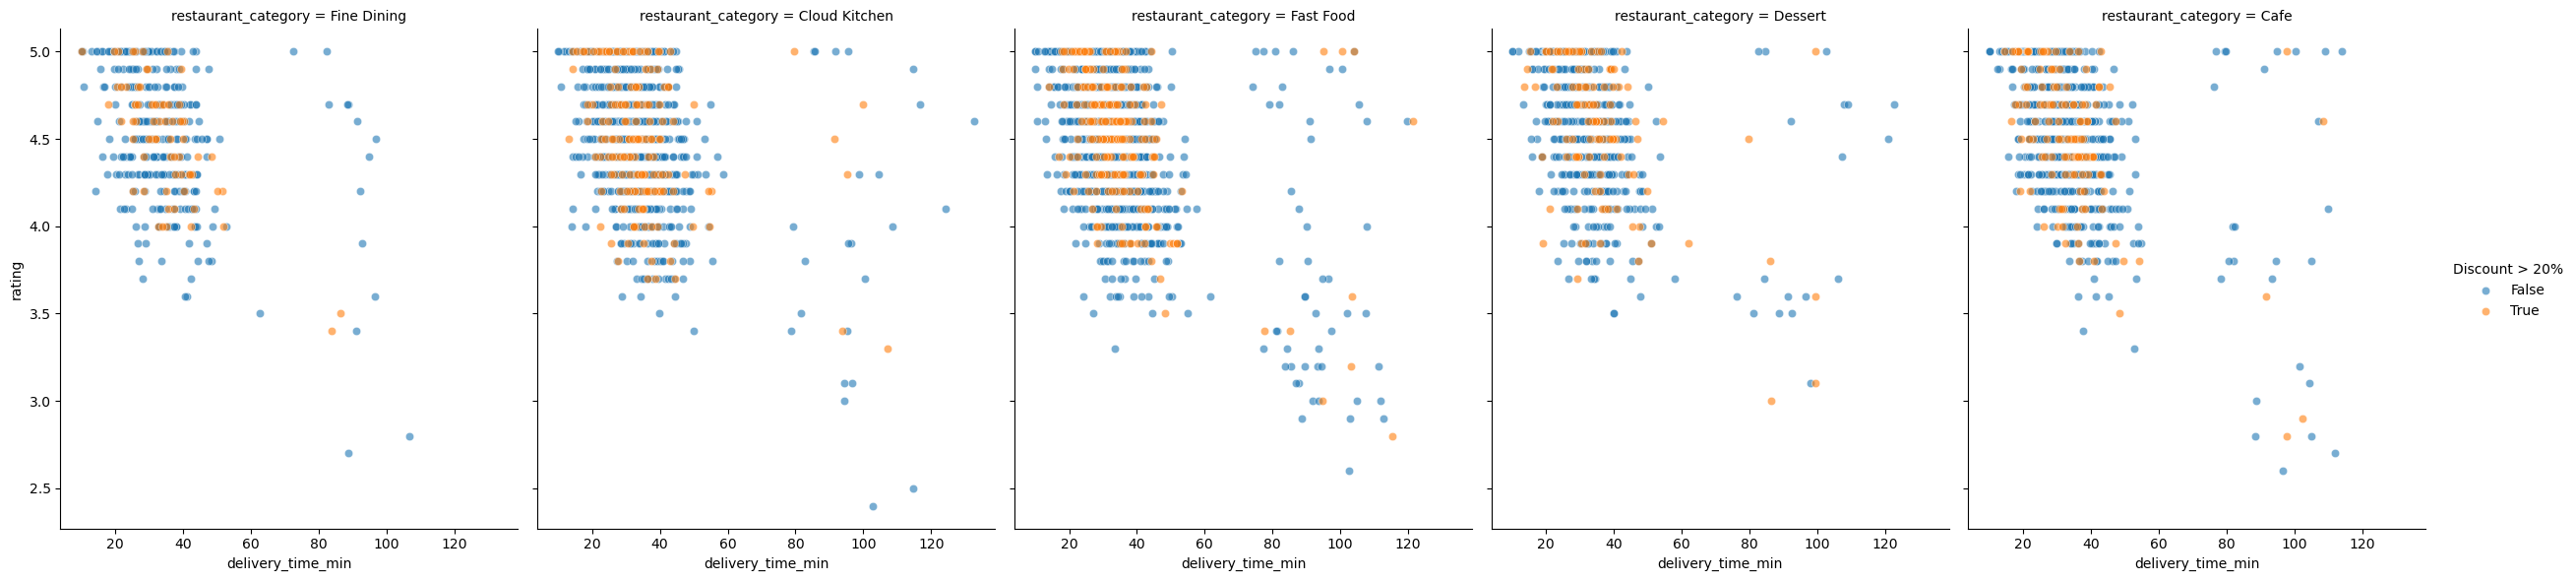

In [20]:
# Task 7
df['heavy_discount'] = df['discount_percent'] > 20

g = sns.FacetGrid(df, col='restaurant_category', hue='heavy_discount', height=5, aspect=1.5)
g.fig.set_size_inches(25, 6) 
g.map(sns.scatterplot, 'delivery_time_min', 'rating', alpha=0.6)
g.add_legend(title="Discount > 20%")
plt.show()

#### In the Cloud Kitchen segment, heavy discounting visibly changes how forgiving customers are of a slow delivery. Specifically, heavily discounted orders (the orange dots) maintain high ratings (mostly 4.0 and above) even as delivery times stretch beyond 80 minutes, whereas non-discounted orders (the blue dots) facing the exact same delays see their ratings plummet.

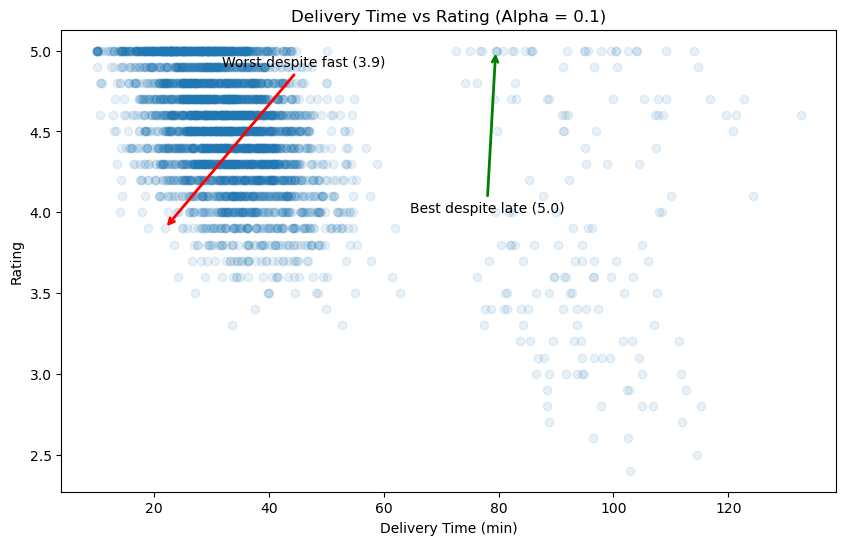

In [10]:
# Task 8

plt.figure(figsize=(10, 6))

# plt.hexbin(df['delivery_time_min'], df['rating'], gridsize=30, cmap='Blues')
plt.scatter(df['delivery_time_min'], df['rating'], alpha=0.1)

long_deliveries = df[df['delivery_time_min'] > df['delivery_time_min'].quantile(0.90)]
best_late = long_deliveries.loc[long_deliveries['rating'].idxmax()]

fast_deliveries = df[df['delivery_time_min'] < df['delivery_time_min'].quantile(0.10)]
worst_fast = fast_deliveries.loc[fast_deliveries['rating'].idxmin()]

plt.annotate(f"Best despite late ({best_late['rating']})", 
             xy=(best_late['delivery_time_min'], best_late['rating']),
             xytext=(best_late['delivery_time_min'] - 15, best_late['rating'] - 1),
             arrowprops=dict(arrowstyle='->', color='green', lw=2))

plt.annotate(f"Worst despite fast ({worst_fast['rating']})", 
             xy=(worst_fast['delivery_time_min'], worst_fast['rating']),
             xytext=(worst_fast['delivery_time_min'] + 10, worst_fast['rating'] + 1),
             arrowprops=dict(arrowstyle='->', color='red', lw=2))

plt.title('Delivery Time vs Rating (Alpha = 0.1)')
plt.xlabel('Delivery Time (min)')
plt.ylabel('Rating')
plt.show()

##### I used transparency (alpha = 0.1) to correct the overplotting because the dataset size is moderate, making this technique the most effective way to reveal actual data density without rendering the scatter plot as a solid, unreadable block. As shown by the annotations, this allows us to clearly isolate and identify specific outliers, such as the order that received a low 3.9 rating despite a fast delivery (~22 minutes), and the order that maintained a perfect 5.0 rating despite a late delivery (~80 minutes).